<a href="https://colab.research.google.com/github/Kufala/Fraud-Detection/blob/main/Sales_Visualization.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
# Models
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier
from sklearn.neural_network import MLPClassifier

In [ ]:
df = pd.read_csv('/content/SuperMarket Analysis.csv')

NameError: name 'pd' is not defined

In [ ]:
df.head()

,Invoice ID,Branch,City,Customer type,Gender,Product line,Unit price,Quantity,Tax 5%,Sales,Date,Time,Payment,cogs,gross margin percentage,gross income,Rating
0,750-67-8428,Alex,Yangon,Member,Female,Health and beauty,74.69,7,26.1415,548.9715,1/5/2019,1:08:00 PM,Ewallet,522.83,4.761905,26.1415,9.1
1,226-31-3081,Giza,Naypyitaw,Normal,Female,Electronic accessories,15.28,5,3.8200,80.2200,3/8/2019,10:29:00 AM,Cash,76.40,4.761905,3.8200,9.6
2,631-41-3108,Alex,Yangon,Normal,Female,Home and lifestyle,46.33,7,16.2155,340.5255,3/3/2019,1:23:00 PM,Credit card,324.31,4.761905,16.2155,7.4
3,123-19-1176,Alex,Yangon,Member,Female,Health and beauty,58.22,8,23.2880,489.0480,1/27/2019,8:33:00 PM,Ewallet,465.76,4.761905,23.2880,8.4
4,373-73-7910,Alex,Yangon,Member,Female,Sports and travel,86.31,7,30.2085,634.3785,2/8/2019,10:37:00 AM,Ewallet,604.17,4.761905,30.2085,5.3


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 17 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Invoice ID               1000 non-null   object 
 1   Branch                   1000 non-null   object 
 2   City                     1000 non-null   object 
 3   Customer type            1000 non-null   object 
 4   Gender                   1000 non-null   object 
 5   Product line             1000 non-null   object 
 6   Unit price               1000 non-null   float64
 7   Quantity                 1000 non-null   int64  
 8   Tax 5%                   1000 non-null   float64
 9   Sales                    1000 non-null   float64
 10  Date                     1000 non-null   object 
 11  Time                     1000 non-null   object 
 12  Payment                  1000 non-null   object 
 13  cogs                     1000 non-null   float64
 14  gross margin percentage  

In [ ]:
df.describe()

,Unit price,Quantity,Tax 5%,Sales,cogs,gross margin percentage,gross income,Rating
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.00000,1.000000e+03,1000.000000,1000.00000
mean,55.672130,5.510000,15.379369,322.966749,307.58738,4.761905e+00,15.379369,6.97270
std,26.494628,2.923431,11.708825,245.885335,234.17651,6.131498e-14,11.708825,1.71858
min,10.080000,1.000000,0.508500,10.678500,10.17000,4.761905e+00,0.508500,4.00000
25%,32.875000,3.000000,5.924875,124.422375,118.49750,4.761905e+00,5.924875,5.50000
50%,55.230000,5.000000,12.088000,253.848000,241.76000,4.761905e+00,12.088000,7.00000
75%,77.935000,8.000000,22.445250,471.350250,448.90500,4.761905e+00,22.445250,8.50000
max,99.960000,10.000000,49.650000,1042.650000,993.00000,4.761905e+00,49.650000,10.00000


In [ ]:
df.isnull().sum()

,0
Invoice ID,0
Branch,0
City,0
Customer type,0
Gender,0
Product line,0
Unit price,0
Quantity,0
Tax 5%,0
Sales,0


In [ ]:
df.head()

,Invoice ID,Branch,City,Customer type,Gender,Product line,Unit price,Quantity,Tax 5%,Sales,Date,Time,Payment,cogs,gross margin percentage,gross income,Rating
0,750-67-8428,Alex,Yangon,Member,Female,Health and beauty,74.69,7,26.1415,548.9715,1/5/2019,1:08:00 PM,Ewallet,522.83,4.761905,26.1415,9.1
1,226-31-3081,Giza,Naypyitaw,Normal,Female,Electronic accessories,15.28,5,3.8200,80.2200,3/8/2019,10:29:00 AM,Cash,76.40,4.761905,3.8200,9.6
2,631-41-3108,Alex,Yangon,Normal,Female,Home and lifestyle,46.33,7,16.2155,340.5255,3/3/2019,1:23:00 PM,Credit card,324.31,4.761905,16.2155,7.4
3,123-19-1176,Alex,Yangon,Member,Female,Health and beauty,58.22,8,23.2880,489.0480,1/27/2019,8:33:00 PM,Ewallet,465.76,4.761905,23.2880,8.4
4,373-73-7910,Alex,Yangon,Member,Female,Sports and travel,86.31,7,30.2085,634.3785,2/8/2019,10:37:00 AM,Ewallet,604.17,4.761905,30.2085,5.3


In [ ]:
# Display Sales and gross income column
df[['Sales','gross income','cogs']]



,Sales,gross income,cogs
0,548.9715,26.1415,522.83
1,80.2200,3.8200,76.40
2,340.5255,16.2155,324.31
3,489.0480,23.2880,465.76
4,634.3785,30.2085,604.17
...,...,...,...
995,42.3675,2.0175,40.35
996,1022.4900,48.6900,973.80
997,33.4320,1.5920,31.84
998,69.1110,3.2910,65.82


In [ ]:
df['City'].unique()

array(['Yangon', 'Naypyitaw', 'Mandalay'], dtype=object)

In [ ]:
df['Branch'].unique()

array(['Alex', 'Giza', 'Cairo'], dtype=object)

In [ ]:
# Calculate Revenue
df['Revenue'] = df['Unit price'] * df['Quantity']

df[['Branch','Revenue']]


,Branch,Revenue
0,Alex,522.83
1,Giza,76.40
2,Alex,324.31
3,Alex,465.76
4,Alex,604.17
...,...,...
995,Giza,40.35
996,Cairo,973.80
997,Alex,31.84
998,Alex,65.82


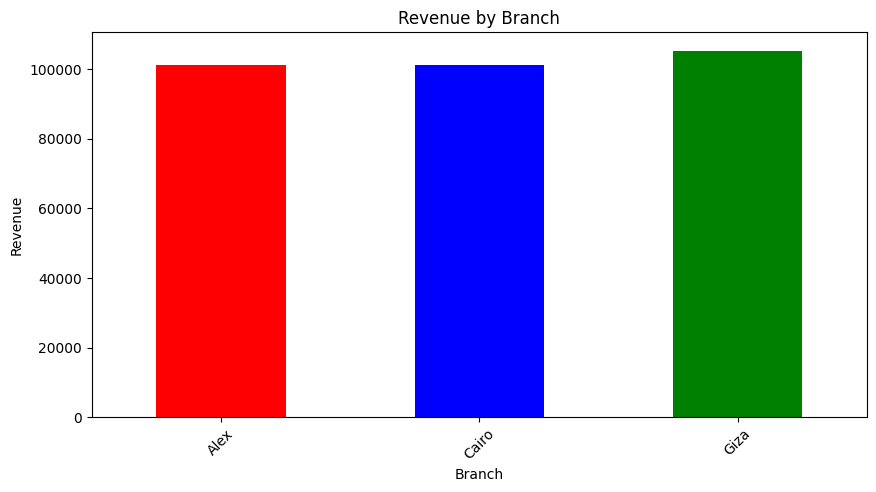

In [ ]:
#Plot bar for City against Revenue
revenue_by_Branch = df.groupby('Branch')['Revenue'].sum()
plt.figure(figsize=(10, 5))

# Create a list of different colors (auto-expands if needed)
colors = ['red', 'blue', 'green', 'orange', 'purple', 'cyan']

revenue_by_Branch.plot(kind='bar', color=colors)

plt.title("Revenue by Branch")
plt.ylabel("Revenue")
plt.xlabel("Branch")
plt.xticks(rotation=45)
plt.show()

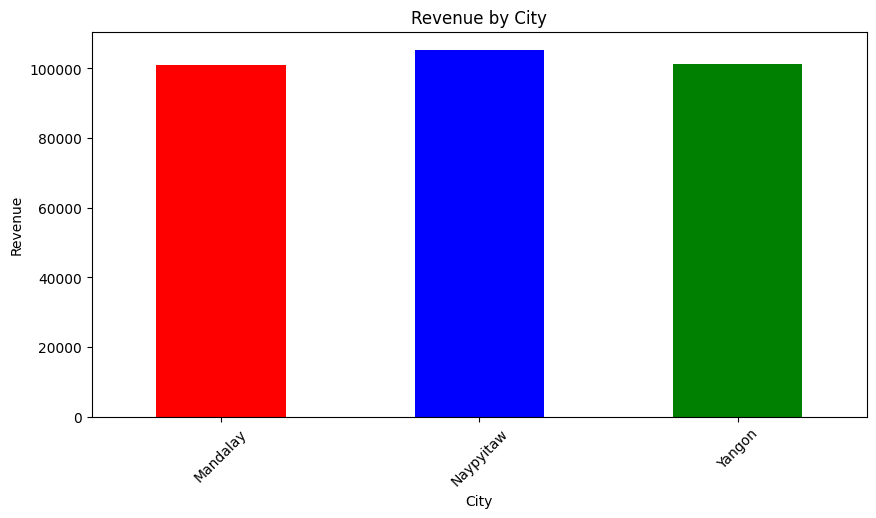

In [ ]:
#Plot bar for City against Revenue
revenue_by_city = df.groupby('City')['Revenue'].sum()
plt.figure(figsize=(10, 5))

# Create a list of different colors (auto-expands if needed)
colors = ['red', 'blue', 'green', 'orange', 'purple', 'cyan']

revenue_by_city.plot(kind='bar', color=colors)

plt.title("Revenue by City")
plt.ylabel("Revenue")
plt.xlabel("City")
plt.xticks(rotation=45)
plt.show()

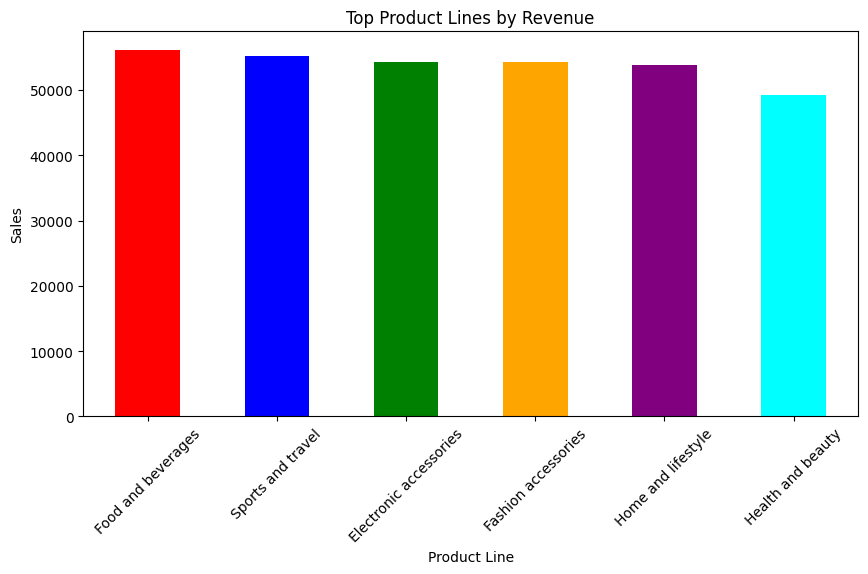

In [ ]:
#BAR PLOT(DIFFERENT COLORS)
#Plot Top production line column By Sales column
top_product_lines = df.groupby('Product line')['Sales'].sum().sort_values(ascending=False)

plt.figure(figsize=(10, 5))

# Create a list of different colors (auto-expands if needed)
colors = ['red', 'blue', 'green', 'orange', 'purple', 'cyan']

top_product_lines.plot(kind='bar', color=colors)

plt.title("Top Product Lines by Revenue")
plt.ylabel("Sales")
plt.xlabel("Product Line")
plt.xticks(rotation=45)
plt.show()

In [ ]:
#Grand total revenue for Alex Branch only
total_revenue_alex = df[df['Branch'] == 'Alex']['Revenue'].sum()
print(total_revenue_alex)



101143.20999999999


In [ ]:
# Total revenue for respective Branch
df.groupby('Branch')['Revenue'].sum()


,Revenue
Branch,
Alex,101143.21
Cairo,101140.64
Giza,105303.53


In [ ]:
total_revenue_alex = df.groupby('Branch')['Revenue'].sum().loc['Alex']
print(total_revenue_alex)


101143.21


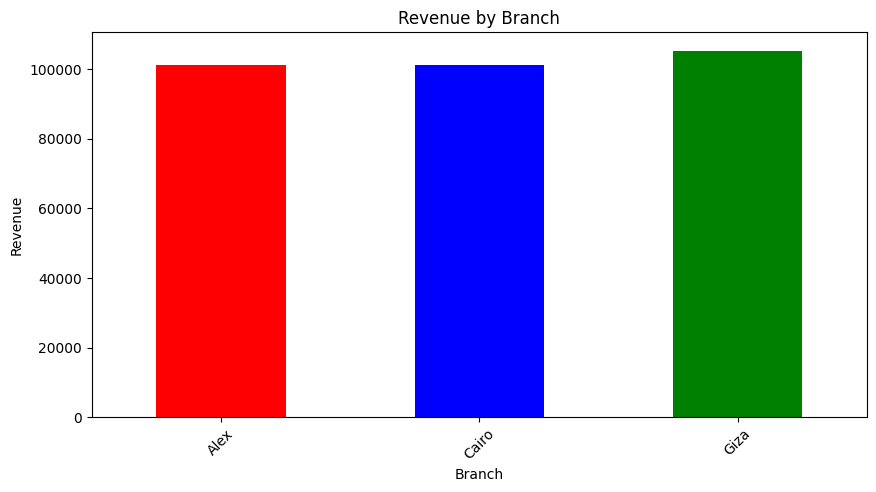

In [ ]:
#Plot bar for City against Revenue
revenue_by_Branch = df.groupby('Branch')['Revenue'].sum()
plt.figure(figsize=(10, 5))

# Create a list of different colors (auto-expands if needed)
colors = ['red', 'blue', 'green', 'orange', 'purple', 'cyan']

revenue_by_Branch.plot(kind='bar', color=colors)

plt.title("Revenue by Branch")
plt.ylabel("Revenue")
plt.xlabel("Branch")
plt.xticks(rotation=45)
plt.show()

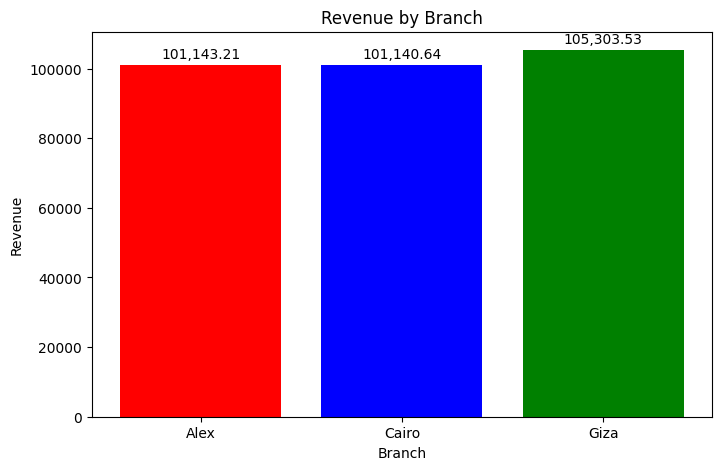

In [ ]:
import matplotlib.pyplot as plt

# Data
branches = ['Alex', 'Cairo', 'Giza']
revenues = [101143.21, 101140.64, 105303.53]

# Plot bar chart
plt.figure(figsize=(8, 5))
bars = plt.bar(branches, revenues, color=['red', 'blue', 'green'])

# Add revenue values on top of bars
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, height + 1000, f'{height:,.2f}',
             ha='center', va='bottom', fontsize=10)

plt.title("Revenue by Branch")
plt.ylabel("Revenue")
plt.xlabel("Branch")
plt.show()


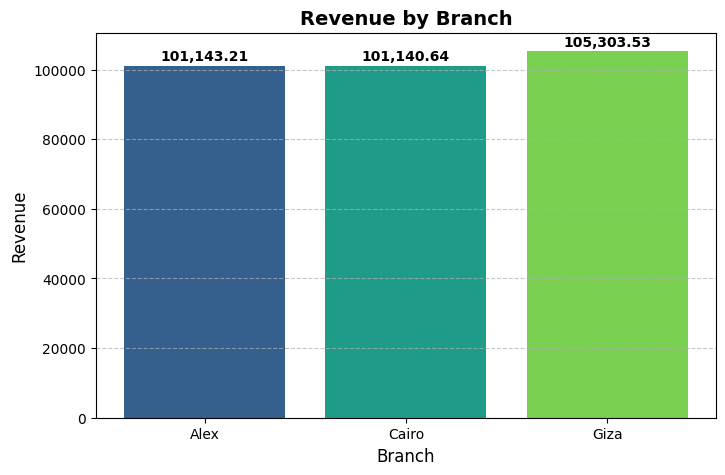

In [ ]:
#Add grid
import matplotlib.pyplot as plt
import numpy as np

# Data
branches = ['Alex', 'Cairo', 'Giza']
revenues = [101143.21, 101140.64, 105303.53]

# Create a color gradient
colors = plt.cm.viridis(np.linspace(0.3, 0.8, len(branches)))  # Viridis colormap

# Plot
plt.figure(figsize=(8, 5))
bars = plt.bar(branches, revenues, color=colors)

# Add revenue values on top
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, height + 500, f'{height:,.2f}',
             ha='center', va='bottom', fontsize=10, fontweight='bold')

# Titles and labels
plt.title("Revenue by Branch", fontsize=14, fontweight='bold')
plt.ylabel("Revenue", fontsize=12)
plt.xlabel("Branch", fontsize=12)

# Optional: add a subtle grid for better readability
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.show()


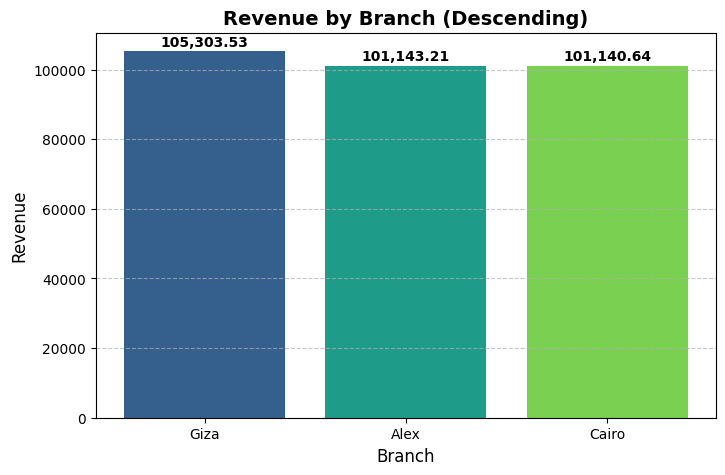

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Data
data = pd.DataFrame({
    'Branch': ['Alex', 'Cairo', 'Giza'],
    'Revenue': [101143.21, 101140.64, 105303.53]
})

# Sort data by Revenue descending
data = data.sort_values(by='Revenue', ascending=False)

# Create a color gradient
colors = plt.cm.viridis(np.linspace(0.3, 0.8, len(data)))

# Plot
plt.figure(figsize=(8, 5))
bars = plt.bar(data['Branch'], data['Revenue'], color=colors)

# Add revenue values on top
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, height + 500, f'{height:,.2f}',
             ha='center', va='bottom', fontsize=10, fontweight='bold')

# Titles and labels
plt.title("Revenue by Branch (Descending)", fontsize=14, fontweight='bold')
plt.ylabel("Revenue", fontsize=12)
plt.xlabel("Branch", fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.show()


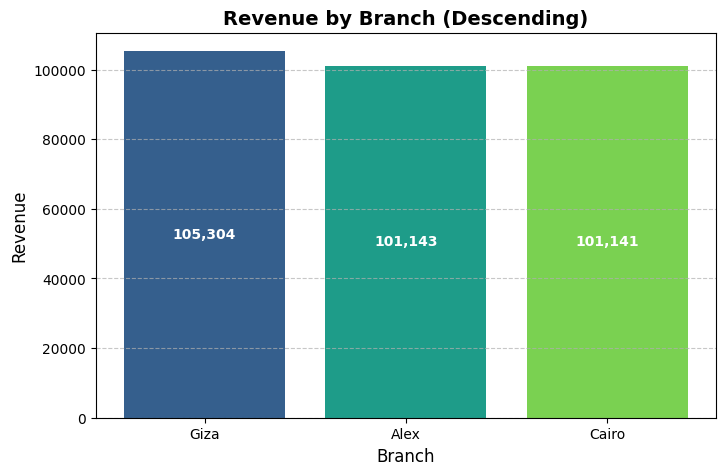

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Data
data = pd.DataFrame({
    'Branch': ['Alex', 'Cairo', 'Giza'],
    'Revenue': [101143.21, 101140.64, 105303.53]
})

# Sort data by Revenue descending
data = data.sort_values(by='Revenue', ascending=False)

# Create a color gradient
colors = plt.cm.viridis(np.linspace(0.3, 0.8, len(data)))

# Plot
plt.figure(figsize=(8, 5))
bars = plt.bar(data['Branch'], data['Revenue'], color=colors)

# Add revenue values inside bars
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width()/2,  # x-position: center of the bar
        height/2,                        # y-position: middle of the bar
        f'{height:,.0f}',                # format without decimals
        ha='center', va='center',        # center alignment
        fontsize=10, color='white',      # white text for contrast
        fontweight='bold'
    )

# Titles and labels
plt.title("Revenue by Branch (Descending)", fontsize=14, fontweight='bold')
plt.ylabel("Revenue", fontsize=12)
plt.xlabel("Branch", fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.show()


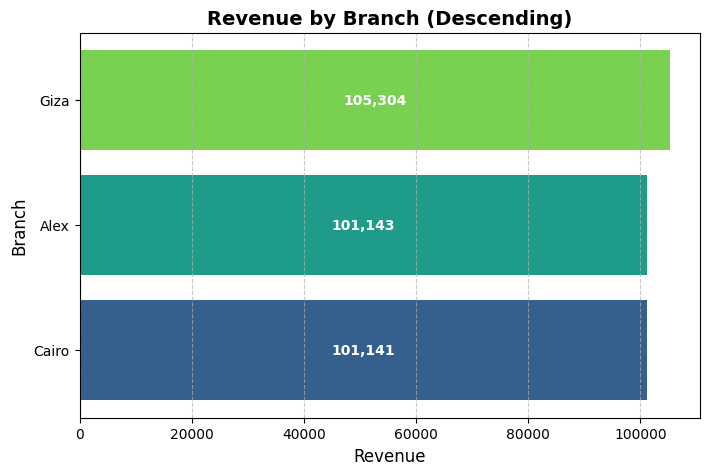

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Data
data = pd.DataFrame({
    'Branch': ['Alex', 'Cairo', 'Giza'],
    'Revenue': [101143.21, 101140.64, 105303.53]
})

# Sort data by Revenue descending
data = data.sort_values(by='Revenue', ascending=True)  # ascending for horizontal bar chart

# Create a color gradient
colors = plt.cm.viridis(np.linspace(0.3, 0.8, len(data)))

# Plot horizontal bar chart
plt.figure(figsize=(8, 5))
bars = plt.barh(data['Branch'], data['Revenue'], color=colors)

# Add revenue values inside bars
for bar in bars:
    width = bar.get_width()
    plt.text(
        width / 2,                       # x-position: middle of the bar
        bar.get_y() + bar.get_height()/2, # y-position: center of the bar
        f'{width:,.0f}',                 # format without decimals
        ha='center', va='center',        # center alignment
        fontsize=10, color='white',      # white text for contrast
        fontweight='bold'
    )

# Titles and labels
plt.title("Revenue by Branch (Descending)", fontsize=14, fontweight='bold')
plt.xlabel("Revenue", fontsize=12)
plt.ylabel("Branch", fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.7)

plt.show()


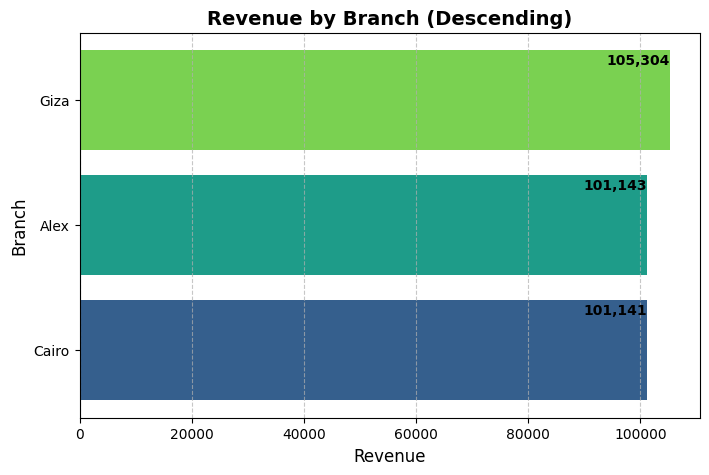

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Data
data = pd.DataFrame({
    'Branch': ['Alex', 'Cairo', 'Giza'],
    'Revenue': [101143.21, 101140.64, 105303.53]
})

# Sort data by Revenue descending
data = data.sort_values(by='Revenue', ascending=True)

# Create a color gradient
colors = plt.cm.viridis(np.linspace(0.3, 0.8, len(data)))

# Plot horizontal bar chart
plt.figure(figsize=(8, 5))
bars = plt.barh(data['Branch'], data['Revenue'], color=colors)

# Add revenue values just below the top of each bar
for bar in bars:
    width = bar.get_width()
    y = bar.get_y() + bar.get_height() * 0.9  # 90% of bar height
    plt.text(
        width,              # x-position: at the end of the bar
        y,                  # y-position: near top of the bar
        f'{width:,.0f}',    # format without decimals
        ha='right',         # align right so it sits just before end
        va='center',        # vertical alignment
        fontsize=10,
        fontweight='bold',
        color='black'
    )

# Titles and labels
plt.title("Revenue by Branch (Descending)", fontsize=14, fontweight='bold')
plt.xlabel("Revenue", fontsize=12)
plt.ylabel("Branch", fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.7)

plt.show()


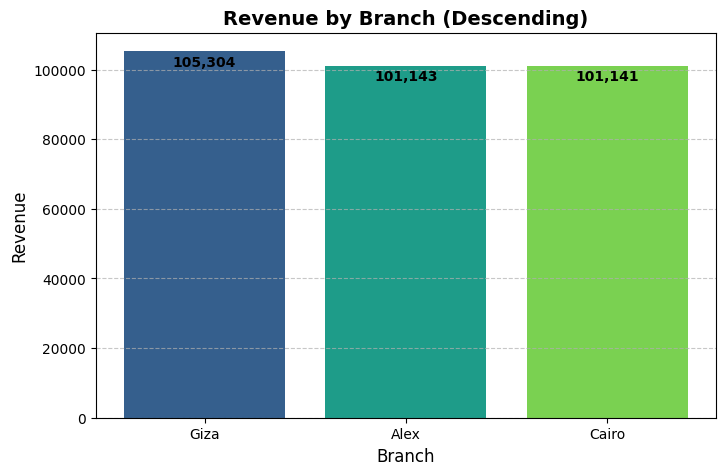

In [ ]:
# Sort data by Revenue descending
data = data.sort_values(by='Revenue', ascending=False)

# Create a color gradient
colors = plt.cm.viridis(np.linspace(0.3, 0.8, len(data)))

# Plot
plt.figure(figsize=(8, 5))
bars = plt.bar(data['Branch'], data['Revenue'], color=colors)

# Add revenue values near the top of each bar
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width()/2,  # x-position: center of the bar
        height * 0.95,                    # y-position: 95% of bar height (near top)
        f'{height:,.0f}',                 # format without decimals
        ha='center', va='bottom',         # center horizontally, bottom of text aligns with y
        fontsize=10, color='black',       # black text for contrast
        fontweight='bold'
    )


# Titles and labels
plt.title("Revenue by Branch (Descending)", fontsize=14, fontweight='bold')
plt.ylabel("Revenue", fontsize=12)
plt.xlabel("Branch", fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.show()


In [ ]:
#DASHBOARD
pip install streamlit


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.2/10.2 MB 47.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.9/6.9 MB 62.4 MB/s eta 0:00:00


2025-11-22 16:01:07.833 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2025-11-22 16:01:07.933 
  command:

    streamlit run /usr/local/lib/python3.12/dist-packages/colab_kernel_launcher.py [ARGUMENTS]
2025-11-22 16:01:07.935 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2025-11-22 16:01:07.936 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2025-11-22 16:01:07.937 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2025-11-22 16:01:07.938 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2025-11-22 16:01:07.939 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2025-11-22 16:01:07.962 Thread 'MainThread': mi

DeltaGenerator()

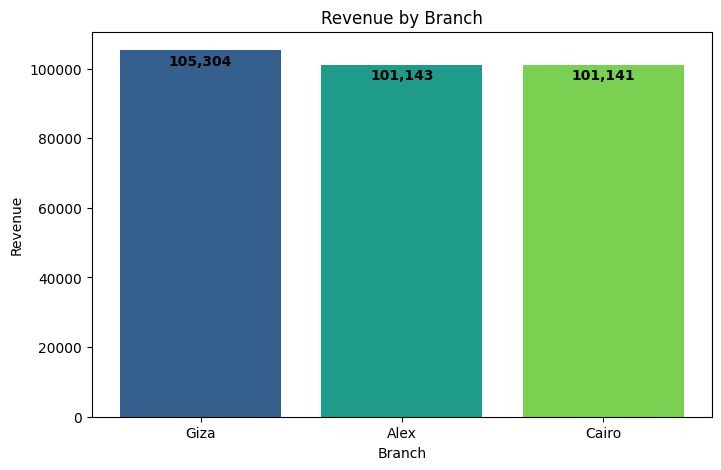

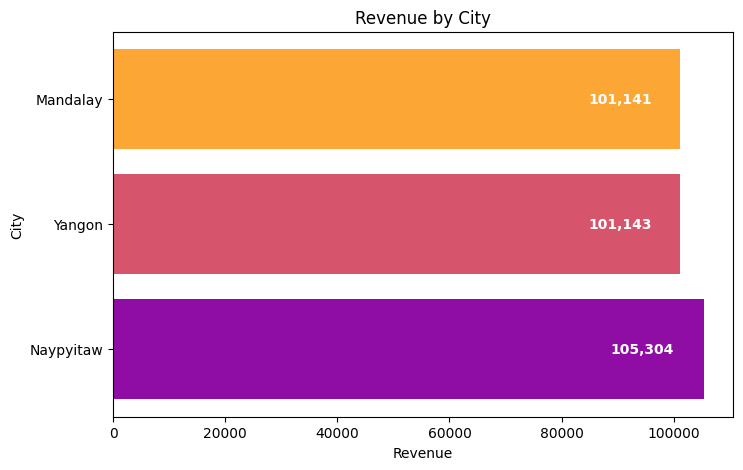

In [ ]:
import streamlit as st
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np



st.title("Sales Dashboard")

# Revenue by Branch
st.subheader("Revenue by Branch")
revenue_by_branch = df.groupby('Branch')['Revenue'].sum().sort_values(ascending=False)

# Plot vertical bar chart
fig, ax = plt.subplots(figsize=(8,5))
bars = ax.bar(revenue_by_branch.index, revenue_by_branch.values, color=plt.cm.viridis(np.linspace(0.3,0.8,len(revenue_by_branch))))

# Add values on top of bars
for bar in bars:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, height*0.95, f'{height:,.0f}', ha='center', va='bottom', fontsize=10, fontweight='bold')

ax.set_ylabel("Revenue")
ax.set_xlabel("Branch")
ax.set_title("Revenue by Branch")
st.pyplot(fig)

# Revenue by City
st.subheader("Revenue by City")
revenue_by_city = df.groupby('City')['Revenue'].sum().sort_values(ascending=False)

fig2, ax2 = plt.subplots(figsize=(8,5))
bars2 = ax2.barh(revenue_by_city.index, revenue_by_city.values, color=plt.cm.plasma(np.linspace(0.3,0.8,len(revenue_by_city))))

# Add values inside bars
for bar in bars2:
    width = bar.get_width()
    ax2.text(width*0.95, bar.get_y() + bar.get_height()/2, f'{width:,.0f}', ha='right', va='center', fontsize=10, fontweight='bold', color='white')

ax2.set_xlabel("Revenue")
ax2.set_ylabel("City")
ax2.set_title("Revenue by City")
st.pyplot(fig2)


In [ ]:
#Save as picture for Dash board
# Example: Save Revenue by Branch plot
fig, ax = plt.subplots(figsize=(8,5))
ax.bar(df['Branch'], df.groupby('Branch')['Revenue'].sum())
plt.title("Revenue by Branch")
plt.savefig("revenue_by_branch.png")  # save as PNG
plt.close(fig)




ValueError: shape mismatch: objects cannot be broadcast to a single shape.  Mismatch is between arg 0 with shape (1000,) and arg 1 with shape (3,).